# Stock Risk Report

In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"
metrics_path = None

In [2]:
# Parameters
ticker = "MRK"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/jin/school/UCB MFE/Prereq Classes/Python/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Min_Jin/data/data.db"
metrics_path = "/Users/jin/school/UCB MFE/Prereq Classes/Python/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Min_Jin/reports/2026-10-30/metrics/MRK_metrics.json"


In [3]:
import json
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

# Constant for function implementation
TRADING_DAYS = 252
VOL_WINDOW = 20
MA_WINDOW = 50
RISK_FREE_RATE = 0.02

## 2.2 Data Loading

In [4]:
# Read one ticker from cleaned ohlc table within [start_date, end_date]
def load_prices(ticker, start_date, end_date, db_path):
    query = """
        SELECT ts, open, high, low, close, adj_close, volume
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts BETWEEN ? AND ?
        ORDER BY ts
    """
    # load data into df
    with sqlite3.connect(db_path) as conn:
        df = pd.read_sql(query, conn, params=(ticker, start_date, end_date))
        # get last trading day in the dataset
        db_last = pd.read_sql(
            "SELECT MAX(ts) AS d FROM ohlc_hw_cleaned WHERE ts BETWEEN ? AND ?",
            conn, params=(start_date, end_date))["d"][0]
    df["ts"] = pd.to_datetime(df["ts"])
    return df.set_index("ts"), db_last

prices_df, db_last = load_prices(ticker, start_date, end_date, db_path)
n_days = len(prices_df)

# error handling in case of no data for the ticker
if n_days == 0:
    raise ValueError(f"No data for {ticker} between {start_date} and {end_date}.")

# find range 
first_obs = prices_df.index.min().date()
last_obs = prices_df.index.max().date()
print(f"{ticker} from {start_date} to {end_date}: {n_days} trading days")
print(f"Actual coverage: {first_obs} to {last_obs}")

# check observed history ends before database's last trading day
if str(last_obs) < db_last:
    print(f"supplied history for {ticker} ends on {last_obs} before the database's last " +
          f"trading day ({db_last})")

# sufficient history for 20-day rolling volatility
if n_days < VOL_WINDOW + 1:
    print(f"Only {n_days} prices. {VOL_WINDOW} returns require at least {VOL_WINDOW+1} prices.")

MRK from 2024-06-01 to 2024-11-30: 126 trading days
Actual coverage: 2024-06-03 to 2024-11-29


In [5]:
# show heads and tails
display(prices_df.head())
display(prices_df.tail())

,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,125.77,128.95,125.77,128.42,126.81,7702676
2024-06-04,127.15,129.36,126.88,128.71,127.09,6440167
2024-06-05,128.48,129.94,128.07,129.45,127.82,5009502
2024-06-06,129.16,130.93,128.90,130.52,128.88,8088641
2024-06-07,130.35,131.37,130.21,130.67,129.03,4945600


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-11-22,100.33,101.79,98.93,99.18,99.18,14031200
2024-11-25,100.09,101.74,99.51,101.16,101.16,34659100
2024-11-26,101.48,101.80,99.70,101.62,101.62,9324100
2024-11-27,101.65,103.45,101.64,103.12,103.12,9802200
2024-11-29,102.88,103.04,101.53,101.64,101.64,6081200


## 2.3 Risk Metrics

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns"""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility"""
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak"""
    cum_max = prices.cummax()
    return (prices - cum_max) / cum_max


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio"""
    # (mean * 252 - rf) / (std * sqrt(252))
    r = returns.dropna()
    if len(r) < 2 or r.std() == 0:
        return np.nan
    return (r.mean() * TRADING_DAYS - risk_free_rate) / (r.std() * np.sqrt(TRADING_DAYS))

In [7]:
# use adj_close to report on numbers
adj = prices_df["adj_close"]
returns = calculate_returns(adj)
rolling_vol = calculate_volatility(returns, VOL_WINDOW)
drawdown = calculate_max_drawdown(adj)
sharpe = calculate_sharpe_ratio(returns, RISK_FREE_RATE)

print(f"Log returns: {returns.notna().sum()}; rolling-vol estimates: {rolling_vol.notna().sum()}")
print("Sharpe ratio:", "N/A" if np.isnan(sharpe) else f"{sharpe:.2f}")

Log returns: 125; rolling-vol estimates: 106
Sharpe ratio: -1.93


## 2.4 Visualization

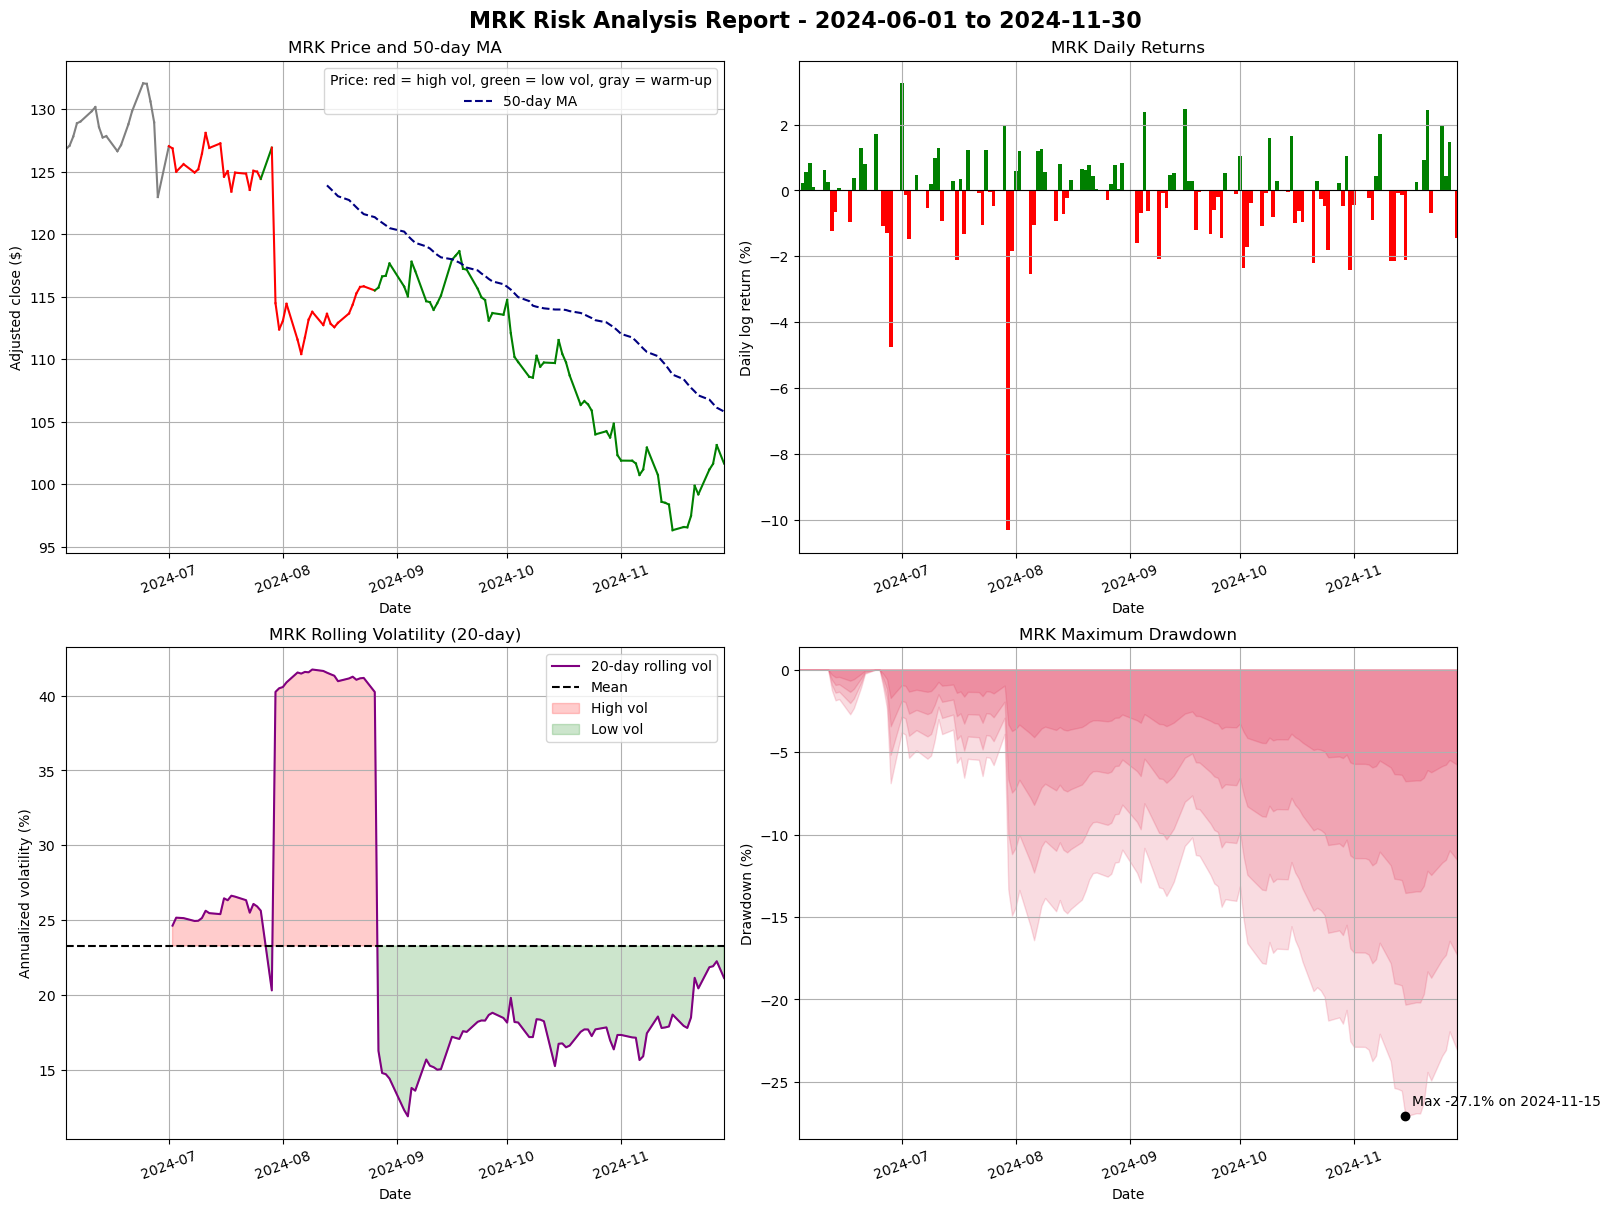

In [8]:
# values used by the charts
ma50 = adj.rolling(MA_WINDOW).mean()
mean_vol = rolling_vol.mean()
max_dd = drawdown.min()
max_dd_date = drawdown.idxmin()

# plots setup
fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout="constrained")
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=16, fontweight="bold")

# Top left - price colored by volatility + 50-day MA
for i in range(1, len(adj)):
    vol = rolling_vol.iloc[i]
    # grey - unavailable, red - high volatility, green - low volatility
    color = "gray" if pd.isna(vol) or pd.isna(mean_vol) else ("red" if vol > mean_vol else "green")
    axes[0, 0].plot(adj.index[i-1:i+1], adj.iloc[i-1:i+1], color=color)
axes[0, 0].plot(ma50.index, ma50, color="navy", linestyle="--", label="50-day MA")

# missing data handling
if ma50.notna().sum() == 0:
    axes[0, 0].set_xlabel(f"Date  (50-day MA unavailable: only {n_days} prices)")
axes[0, 0].set(title=f"{ticker} Price and 50-day MA", ylabel="Adjusted close ($)")
axes[0, 0].legend(title="Price: red = high vol, green = low vol, gray = warm-up")

# Top right - daily returns bar chart
axes[0, 1].bar(returns.index, returns * 100, width=1, color=np.where(returns >= 0, "green", "red"))
axes[0, 1].axhline(0, color="black", linewidth=0.8)
axes[0, 1].set(title=f"{ticker} Daily Returns", ylabel="Daily log return (%)")

# Bottom left - rolling volatility with mean line and shading
vol_pct = rolling_vol * 100
axes[1, 0].plot(vol_pct.index, vol_pct, color="purple", label="20-day rolling vol")
axes[1, 0].axhline(mean_vol * 100, color="black", linestyle="--", label="Mean")
axes[1, 0].fill_between(vol_pct.index, vol_pct, mean_vol * 100, where=rolling_vol > mean_vol,
                        color="red", alpha=0.2, interpolate=True, label="High vol")
axes[1, 0].fill_between(vol_pct.index, vol_pct, mean_vol * 100, where=rolling_vol <= mean_vol,
                        color="green", alpha=0.2, interpolate=True, label="Low vol")
axes[1, 0].set(title=f"{ticker} Rolling Volatility (20-day)", ylabel="Annualized volatility (%)")
# missing data handling
if rolling_vol.notna().sum() == 0:
    axes[1, 0].text(0.5, 0.5, f"Rolling volatility unavailable\n(needs at least {VOL_WINDOW + 1} prices)",
                    transform=axes[1, 0].transAxes, ha="center")
axes[1, 0].legend()

# Bottom right: drawdown area with layered red fills and max point
dd_pct = drawdown * 100
for fraction in [1.0, 0.75, 0.5, 0.25]:
    axes[1, 1].fill_between(dd_pct.index, dd_pct * fraction, 0, color="crimson", alpha=0.15)
axes[1, 1].scatter([max_dd_date], [max_dd * 100], color="black", zorder=3)
axes[1, 1].annotate(f"Max {max_dd:.1%} on {max_dd_date.date()}", (max_dd_date, max_dd * 100),
                    xytext=(5, 8), textcoords="offset points")
axes[1, 1].set(title=f"{ticker} Maximum Drawdown", ylabel="Drawdown (%)")

# plot all 4 charts
for ax in axes.flat:
    if not ax.get_xlabel():
        ax.set_xlabel("Date")
    ax.grid(True)
    # same date range on every panel
    ax.set_xlim(adj.index[0], adj.index[-1])
    ax.tick_params(axis="x", labelrotation=20)
plt.show()

## 2.5 Summary Statistics

In [9]:
def summary_stats(adj, returns):
    """summary statistics for reporting"""
    r = returns.dropna()
    n = len(r)
    up, down = r[r > 0], r[r < 0]
    return {
        # total return: last_adjusted_close / first_adjusted_close - 1
        "Total Return": adj.iloc[-1] / adj.iloc[0] - 1 if len(adj) >= 2 else np.nan,
        # annualized return: exp(sum(log_returns) * 252 / n) - 1
        "Annualized Return": np.exp(r.sum() * TRADING_DAYS / n) - 1 if n > 0 else np.nan,
        # annualized vol: std(log_returns) * sqrt(252)
        "Annualized Volatility": r.std() * np.sqrt(TRADING_DAYS) if n >= 2 else np.nan,
        "Sharpe Ratio": calculate_sharpe_ratio(returns, RISK_FREE_RATE),
        "Maximum Drawdown": calculate_max_drawdown(adj).min(),
        "Best Day": r.max() if n > 0 else np.nan,
        "Worst Day": r.min() if n > 0 else np.nan,
        "Positive Days": len(up) / n if n > 0 else np.nan,
        "Average Up Day": up.mean() if len(up) > 0 else np.nan,
        "Average Down Day": down.mean() if len(down) > 0 else np.nan,
    }

stats = summary_stats(adj, returns)

# format numbers for display
summary_table = pd.DataFrame({
    "Metric": list(stats),
    "Value": [
        f"{stats['Total Return']:+.2%}",
        f"{stats['Annualized Return']:+.2%}",
        f"{stats['Annualized Volatility']:.2%}",
        f"{stats['Sharpe Ratio']:.2f}",
        f"{stats['Maximum Drawdown']:+.2%}",
        f"{stats['Best Day']:+.2%}",
        f"{stats['Worst Day']:+.2%}",
        f"{stats['Positive Days']:.1%}",
        f"{stats['Average Up Day']:+.2%}",
        f"{stats['Average Down Day']:+.2%}",
    ],
})
# an empty up/down subset displays N/A
summary_table["Value"] = summary_table["Value"].str.replace(r".*nan.*", "N/A", regex=True)

# display the summary statistics
print(f"{ticker}: from {start_date} to {end_date}; actual trading days from {first_obs} to {last_obs} ({n_days} trading days)")
display(summary_table.style.hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

MRK: from 2024-06-01 to 2024-11-30; actual trading days from 2024-06-03 to 2024-11-29 (126 trading days)


Metric,Value
Total Return,-19.85%
Annualized Return,-35.98%
Annualized Volatility,24.09%
Sharpe Ratio,-1.93
Maximum Drawdown,-27.08%
Best Day,+3.26%
Worst Day,-10.32%
Positive Days,47.2%
Average Up Day,+0.87%
Average Down Day,-1.11%


## Metrics for the batch summary
When this notebook is run by `03_run_all_stocks.py`, this cell saves the report's key metrics to a JSON file so the batch script can build the portfolio summary.

In [10]:
# Named outputs for the batch summary in Part 3
if metrics_path:
    metrics = {
        "ticker": ticker,
        "requested_start": start_date, "requested_end": end_date,
        "first_obs": str(first_obs), "last_obs": str(last_obs), "trading_days": n_days,
        "avg_daily_return": float(returns.mean()),
        # undefined number store as None for JSON
        "avg_volatility": None if np.isnan(mean_vol) else float(mean_vol),
        "max_drawdown": float(max_dd),
        "sharpe_ratio": None if np.isnan(sharpe) else float(sharpe),
        "total_return": float(stats["Total Return"]),
    }

    # dump data into json for summary analysis
    with open(metrics_path, "w") as f:
        json.dump(metrics, f, indent=2)
    print("Metrics written to", metrics_path)

Metrics written to /Users/jin/school/UCB MFE/Prereq Classes/Python/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Min_Jin/reports/2026-10-30/metrics/MRK_metrics.json
